# Laboratorio 4. Segmentación de imágenes con técnicas de agrupación

**Caso: DermAlpes — segmentación no supervisada de lesiones dermatoscópicas**

**Integrantes:** Angel Felipe Restrepo Castillo — 201914073 · Laura Valentina Jimenez Tovar — 201924116

## Fuente de los datos

El laboratorio entrega una selección de 20 imágenes dermatoscópicas de ISIC 2016, cada una acompañada de una máscara binaria de referencia. La documentación oficial de ISIC para la tarea 1 describe las imágenes JPEG y las máscaras PNG de un canal, con valores 0 para fondo y 255 para lesión, y dimensiones coincidentes entre cada par.

**Referencia del conjunto de datos:** Gutman, D., Codella, N. C. F., Celebi, E., Helba, B., Marchetti, M., Mishra, N. y Halpern, A. (2016). *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC).* https://challenge.isic-archive.com/landing/2016/37/.

## 0. Importación de librerías

Se utilizan NumPy para representar los píxeles, Pillow para cargar y redimensionar las imágenes, Matplotlib para las visualizaciones, Pandas para las tablas y Scikit-learn para el pipeline, K-medias, silueta, V-measure, Dice/F1, precisión, recall y PCA.

Se fija `RANDOM_STATE = 2026` para que las inicializaciones de K-medias, las muestras de silueta y las muestras de los bonos puedan reproducirse. La resolución máxima de trabajo se fija en 160 píxeles por lado; se conserva la relación de aspecto original, por lo que el tamaño final puede variar ligeramente entre imágenes.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import (
    silhouette_score,
    f1_score,
    v_measure_score,
    precision_score,
    recall_score,
    pairwise_distances_argmin
)
from sklearn.decomposition import PCA

RANDOM_STATE = 2026
MAX_IMAGE_SIDE = 160
K_VALUES = range(2, 9)
SILHOUETTE_SAMPLE_SIZE = 1000

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Resolución máxima de trabajo:", MAX_IMAGE_SIDE, "píxeles")
print("Muestra reproducible para silueta:", SILHOUETTE_SAMPLE_SIZE)
print("Semilla:", RANDOM_STATE)

NumPy: 2.2.4
Pandas: 2.2.3
Resolución máxima de trabajo: 160 píxeles
Muestra reproducible para silueta: 1000
Semilla: 2026


## 1. Carga de datos y separación entre ajuste y prueba

In [2]:
DATA_DIR = Path("Data")

TRAIN_IDS = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094",
    "ISIC_0000108", "ISIC_0000114", "ISIC_0000116", "ISIC_0000122",
    "ISIC_0000133", "ISIC_0000137", "ISIC_0000150", "ISIC_0000153",
    "ISIC_0000156", "ISIC_0000157", "ISIC_0000112"
]

TEST_IDS = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110",
    "ISIC_0000123", "ISIC_0000128"
]

all_image_ids = sorted(path.stem for path in DATA_DIR.glob("ISIC_*.jpg"))

assert len(TRAIN_IDS) == 15
assert len(TEST_IDS) == 5
assert len(set(TRAIN_IDS + TEST_IDS)) == 20

print("Imágenes JPEG encontradas:", len(all_image_ids))
print("Pares imagen-máscara requeridos:", len(TRAIN_IDS) + len(TEST_IDS))
print("Imágenes de ajuste:", len(TRAIN_IDS))
print("Imágenes de prueba:", len(TEST_IDS))
print("Identificadores de ajuste:", TRAIN_IDS)
print("Identificadores de prueba:", TEST_IDS)

Imágenes JPEG encontradas: 20
Pares imagen-máscara requeridos: 20
Imágenes de ajuste: 15
Imágenes de prueba: 5
Identificadores de ajuste: ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108', 'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137', 'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
Identificadores de prueba: ['ISIC_0000087', 'ISIC_0000105', 'ISIC_0000110', 'ISIC_0000123', 'ISIC_0000128']


## 2. Exploración visual inicial

Primero se observan las imágenes originales de los dos conjuntos, identificando variaciones de color, tamaño, forma y contraste. Esta inspección sirve para entender la diversidad de las entradas, no para escoger parámetros a partir de las imágenes de prueba. En esta etapa no se muestran ni se consultan sus máscaras.

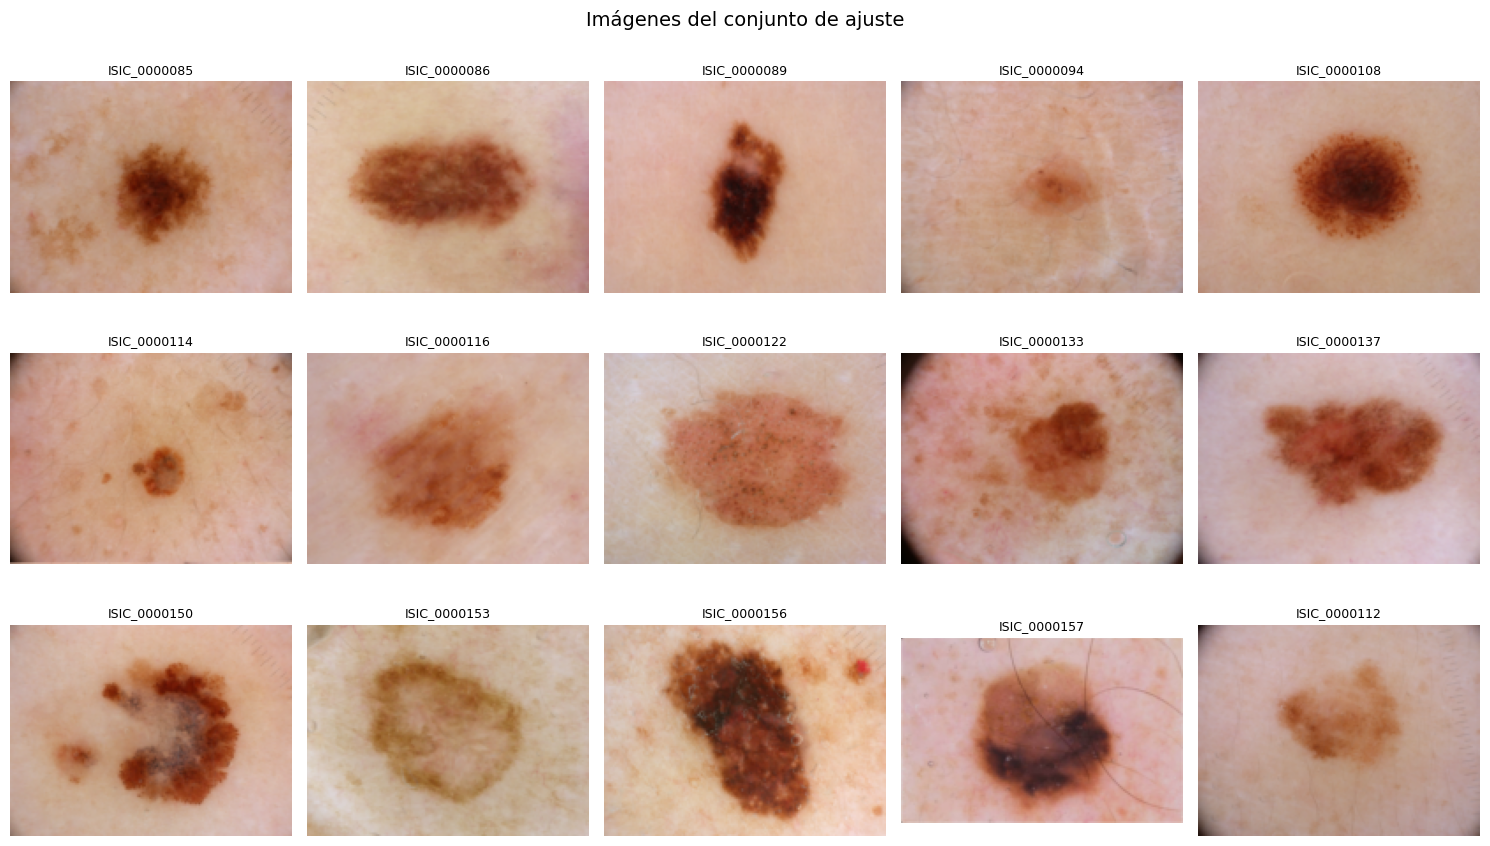

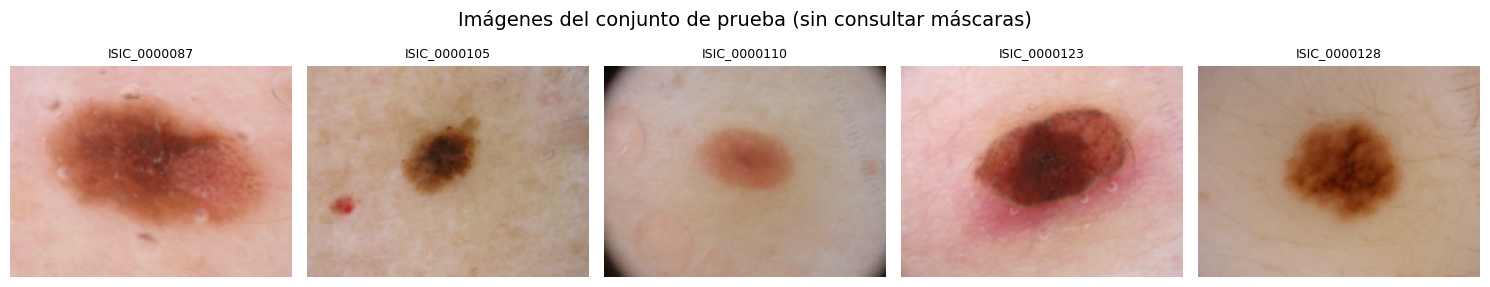

In [3]:
def load_image(image_id):
    """Carga y reduce una imagen RGB conservando la relación de aspecto."""
    image_path = DATA_DIR / f"{image_id}.jpg"
    image = Image.open(image_path).convert("RGB")

    scale = MAX_IMAGE_SIDE / max(image.size)
    new_size = (
        max(1, round(image.width * scale)),
        max(1, round(image.height * scale))
    )
    image = image.resize(new_size, Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.uint8)


def load_reference_mask(image_id, target_size):
    """Carga la máscara y la redimensiona con vecino más cercano."""
    mask_path = DATA_DIR / f"{image_id}_Segmentation.png"
    mask = Image.open(mask_path).convert("L")
    mask = mask.resize(target_size, Image.Resampling.NEAREST)
    # El formato original codifica fondo=0 y lesión=255.
    return (np.asarray(mask, dtype=np.uint8) >= 128).astype(np.uint8)


def load_image_and_mask(image_id):
    image = load_image(image_id)
    mask = load_reference_mask(image_id, (image.shape[1], image.shape[0]))
    assert image.shape[:2] == mask.shape
    return image, mask


def show_image_grid(image_ids, title, columns=5):
    rows = int(np.ceil(len(image_ids) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.0 * rows))
    axes = np.asarray(axes).reshape(-1)

    for ax, image_id in zip(axes, image_ids):
        image = load_image(image_id)
        ax.imshow(image)
        ax.set_title(image_id, fontsize=9)
        ax.axis("off")

    for ax in axes[len(image_ids):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_image_grid(TRAIN_IDS, "Imágenes del conjunto de ajuste")
show_image_grid(TEST_IDS, "Imágenes del conjunto de prueba (sin consultar máscaras)")

## 3. Pipeline de preparación y representación de píxeles

Cada imagen se convierte en una matriz de `H × W` filas y cinco columnas. Las tres primeras columnas son RGB normalizado a `[0, 1]`, multiplicado por `β`; las dos últimas son las coordenadas `x, y`, normalizadas al mismo intervalo y multiplicadas por `λ`:

La representación de cada píxel queda como: `X_pixel = [β·R, β·G, β·B, λ·x, λ·y]`.

La transformación se implementa como un transformador de Scikit-learn y se conecta a K-medias mediante `Pipeline`. Así, modificar `β` o `λ` no exige cambiar el código de representación. Con `λ=0` se anula la posición; con `β=0` se anula el color.

Las máscaras se convierten a valores 0 y 1 y se mantienen alineadas con la imagen reducida. Se usa vecino más cercano porque la interpolación debe conservar las etiquetas binarias, sin crear valores intermedios.

In [4]:
class PixelFeatureTransformer(BaseEstimator, TransformerMixin):
    """Transforma una imagen RGB en una fila de características por píxel."""

    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, image, y=None):
        return self

    def transform(self, image):
        image = np.asarray(image, dtype=np.float32)
        if image.ndim != 3 or image.shape[2] != 3:
            raise ValueError("La entrada debe ser una imagen RGB de dimensiones H x W x 3.")

        height, width = image.shape[:2]
        rgb = image.reshape(-1, 3) / 255.0

        y_coordinates, x_coordinates = np.mgrid[0:height, 0:width]
        coordinates = np.column_stack((
            x_coordinates.ravel() / max(width - 1, 1),
            y_coordinates.ravel() / max(height - 1, 1)
        )).astype(np.float32)

        return np.column_stack((
            self.beta * rgb,
            self.lam * coordinates
        )).astype(np.float32)


def build_kmeans_pipeline(beta, lam, k):
    return Pipeline([
        ("pixel_features", PixelFeatureTransformer(beta=beta, lam=lam)),
        ("kmeans", KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=3,
            max_iter=100,
            algorithm="lloyd"
        ))
    ])


# Comprobación de dimensiones, normalización y correspondencia de las máscaras.
sample_image, sample_mask = load_image_and_mask(TRAIN_IDS[0])
sample_features = PixelFeatureTransformer(beta=1.0, lam=0.75).fit_transform(sample_image)

print("Dimensiones de la imagen:", sample_image.shape)
print("Dimensiones de la máscara:", sample_mask.shape)
print("Matriz de características:", sample_features.shape)
print("Filas esperadas (H x W):", sample_image.shape[0] * sample_image.shape[1])
print("Mínimo y máximo RGB normalizado:", sample_image.min() / 255, sample_image.max() / 255)
print("Mínimo y máximo de las coordenadas normalizadas:",
      sample_features[:, 3:].min(), sample_features[:, 3:].max())
print("Valores de la máscara:", np.unique(sample_mask))

assert sample_features.shape == (sample_image.shape[0] * sample_image.shape[1], 5)
assert set(np.unique(sample_mask)).issubset({0, 1})

Dimensiones de la imagen: (120, 160, 3)
Dimensiones de la máscara: (120, 160)
Matriz de características: (19200, 5)
Filas esperadas (H x W): 19200
Mínimo y máximo RGB normalizado: 0.00784313725490196 0.8392156862745098
Mínimo y máximo de las coordenadas normalizadas: 0.0 0.75
Valores de la máscara: [0 1]


### Justificación del tamaño de trabajo

Las imágenes originales tienen dimensiones de megapíxeles. Ejecutar 1.050 modelos sobre todos esos píxeles elevaría innecesariamente el costo de la búsqueda. Se fija el lado mayor en 160 píxeles, sin deformar la imagen. La máscara usa vecino más cercano y conserva únicamente 0 y 1. Por tanto, las métricas que se reportan corresponden a esta resolución de trabajo y no deben interpretarse como una medición de contornos a resolución clínica original.

In [5]:
dimension_rows = []
for image_id in TRAIN_IDS + TEST_IDS:
    original = Image.open(DATA_DIR / f"{image_id}.jpg")
    reduced = load_image(image_id)
    dimension_rows.append({
        "imagen": image_id,
        "dimensiones originales (H x W)": f"{original.height} x {original.width}",
        "dimensiones de trabajo (H x W)": f"{reduced.shape[0]} x {reduced.shape[1]}"
    })

display(pd.DataFrame(dimension_rows))

,imagen,dimensiones originales (H x W),dimensiones de trabajo (H x W)
0,ISIC_0000085,1536 x 2048,120 x 160
1,ISIC_0000086,1944 x 2592,120 x 160
2,ISIC_0000089,1536 x 2048,120 x 160
3,ISIC_0000094,1536 x 2048,120 x 160
4,ISIC_0000108,1536 x 2048,120 x 160
5,ISIC_0000114,1536 x 2048,120 x 160
6,ISIC_0000116,1536 x 2048,120 x 160
7,ISIC_0000122,1536 x 2048,120 x 160
8,ISIC_0000133,1536 x 2048,120 x 160
9,ISIC_0000137,1536 x 2048,120 x 160


## 4. Selección de `K` mediante coeficiente de silueta

Para cada imagen de ajuste y cada combinación de pesos se entrena K-medias con `K = 2, 3, …, 8`. Cada modelo se ajusta sobre todos los píxeles de la imagen reducida; el coeficiente de silueta se calcula sobre una muestra aleatoria reproducible de hasta 1.000 píxeles. Se selecciona el `K` con mayor silueta para esa imagen y combinación.

Se exploran diez combinaciones con razones `λ/β` distintas, incluyendo explícitamente solo color y solo posición. Se mantiene `β = 1` para las combinaciones mixtas y se varía `λ`; esto cambia la importancia relativa de las coordenadas frente al color, sin repetir combinaciones equivalentes por multiplicación común de ambos pesos.

El valor de silueta se usa únicamente para escoger `K`. No identifica qué clúster representa la lesión; esa decisión se aborda en la actividad siguiente.

In [6]:
CONFIGURATIONS = [
    {"name": "Solo color",       "beta": 1.0, "lam": 0.00},
    {"name": "Color + posición", "beta": 1.0, "lam": 0.05},
    {"name": "Color + posición", "beta": 1.0, "lam": 0.10},
    {"name": "Color + posición", "beta": 1.0, "lam": 0.25},
    {"name": "Color + posición", "beta": 1.0, "lam": 0.50},
    {"name": "Color + posición", "beta": 1.0, "lam": 0.75},
    {"name": "Color + posición", "beta": 1.0, "lam": 1.00},
    {"name": "Color + posición", "beta": 1.0, "lam": 1.50},
    {"name": "Color + posición", "beta": 1.0, "lam": 2.00},
    {"name": "Solo posición",    "beta": 0.0, "lam": 1.00}
]

ratios = [
    ("∞ (solo posición)" if c["beta"] == 0 else c["lam"] / c["beta"])
    for c in CONFIGURATIONS
]

for config, ratio in zip(CONFIGURATIONS, ratios):
    config["lambda/beta"] = ratio

display(pd.DataFrame(CONFIGURATIONS))

,name,beta,lam,lambda/beta
0,Solo color,1.0,0.00,0.0
1,Color + posición,1.0,0.05,0.05
2,Color + posición,1.0,0.10,0.1
3,Color + posición,1.0,0.25,0.25
4,Color + posición,1.0,0.50,0.5
5,Color + posición,1.0,0.75,0.75
6,Color + posición,1.0,1.00,1.0
7,Color + posición,1.0,1.50,1.5
8,Color + posición,1.0,2.00,2.0
9,Solo posición,0.0,1.00,∞ (solo posición)


In [7]:
def fit_best_k(image, beta, lam):
    """
    Ajusta K-medias para K=2,...,8 y escoge el K de mayor silueta.
    La referencia no se recibe como argumento y, por tanto, no interviene
    en la selección de K.
    """
    feature_matrix = PixelFeatureTransformer(beta=beta, lam=lam).fit_transform(image)
    best = None
    score_records = []

    for k in K_VALUES:
        pipeline = build_kmeans_pipeline(beta, lam, k)
        labels = pipeline.fit_predict(image)

        score = silhouette_score(
            feature_matrix,
            labels,
            sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(labels)),
            random_state=RANDOM_STATE
        )
        score_records.append({
            "K": k,
            "silueta": float(score)
        })

        if best is None or score > best["silhouette"]:
            best = {
                "K": k,
                "silhouette": float(score),
                "labels": labels.copy(),
                "pipeline": pipeline,
                "features": feature_matrix
            }

    return best, score_records


def dice_coefficient(reference, prediction):
    # Dice binario equivale a F1-score usando lesión como clase positiva.
    return f1_score(
        reference.ravel(),
        prediction.ravel(),
        zero_division=0
    )


def cluster_masks(image, labels, k):
    """
    Criterio A: el grupo admisible con menor luminancia promedio.
    Criterio B: puntuación conjunta de oscuridad, centralidad y tamaño.
    """
    height, width = image.shape[:2]
    rgb = image.reshape(-1, 3).astype(np.float32) / 255.0

    y_coordinates, x_coordinates = np.mgrid[0:height, 0:width]
    coordinates = np.column_stack((
        x_coordinates.ravel() / max(width - 1, 1),
        y_coordinates.ravel() / max(height - 1, 1)
    ))

    # Luminancia aproximada a partir del RGB original, antes de ponderar.
    luminance = rgb @ np.array([0.2126, 0.7152, 0.0722], dtype=np.float32)

    counts = np.bincount(labels, minlength=k)
    area_fraction = counts / len(labels)
    mean_luminance = np.array([
        luminance[labels == cluster].mean()
        for cluster in range(k)
    ])

    centroids = np.array([
        coordinates[labels == cluster].mean(axis=0)
        for cluster in range(k)
    ])
    center_distance = (
        np.linalg.norm(centroids - np.array([0.5, 0.5]), axis=1)
        / np.sqrt(0.5)
    )

    # Se descartan grupos diminutos y grupos que cubren casi toda la imagen.
    admissible = (area_fraction >= 0.005) & (area_fraction <= 0.70)
    if not admissible.any():
        admissible = np.ones(k, dtype=bool)

    # Criterio A: se selecciona un único grupo oscuro.
    darkest_cluster = int(np.argmin(np.where(admissible, mean_luminance, np.inf)))
    mask_A = (labels == darkest_cluster).astype(np.uint8).reshape(height, width)

    # Criterio B: se combina contraste de luminancia, centralidad y tamaño.
    global_mean = luminance.mean()
    global_std = luminance.std() + 1e-8
    darkness = np.clip(
        (global_mean - mean_luminance) / global_std,
        -2, 2
    )
    centrality = 1 - center_distance
    size_score = np.clip(
        (np.log(area_fraction + 1e-8) - np.log(0.08)) / 2,
        -1, 1
    )

    cluster_score = (
        0.65 * darkness
        + 0.25 * centrality
        + 0.10 * size_score
    )
    selected_cluster = int(
        np.argmax(np.where(admissible, cluster_score, -np.inf))
    )
    mask_B = (labels == selected_cluster).astype(np.uint8).reshape(height, width)

    return mask_A, mask_B, {
        "luminancia_media": mean_luminance,
        "fraccion_area": area_fraction,
        "distancia_centro": center_distance,
        "puntuacion_B": cluster_score,
        "cluster_A": darkest_cluster,
        "cluster_B": selected_cluster
    }

## 5. Criterios automáticos para construir la máscara de lesión

K-medias produce grupos, pero no les asigna el significado de “lesión” o “piel”. Para construir la máscara se comparan dos reglas automáticas que solo utilizan características de los grupos; ninguna consulta la máscara de referencia para decidir qué grupo seleccionar.

**Criterio A — grupo más oscuro.** Se selecciona el grupo admisible con menor luminancia RGB promedio. Se consideran admisibles los grupos que ocupan entre 0,5 % y 70 % de la imagen. El límite inferior evita seleccionar pequeños grupos residuales y el superior evita considerar como lesión un grupo que cubra prácticamente todo el campo.

**Criterio B — oscuridad, centralidad y tamaño.** Para cada grupo admisible se calcula una puntuación:
La puntuación del grupo se calcula así: `S_c = 0.65 × D_c + 0.25 × C_c + 0.10 × T_c`.
donde `D_c` es el contraste de oscuridad respecto al promedio de la imagen (normalizado por su desviación estándar y limitado a `[-2, 2]`); `C_c` es la cercanía del centroide al centro de la imagen; y `T_c` es una puntuación acotada basada en la fracción de área del grupo. Se elige el grupo de mayor puntuación.

El segundo criterio incorpora una hipótesis espacial razonable para imágenes dermatoscópicas centradas, pero puede perjudicar lesiones periféricas. Los pesos y límites se fijan antes de la evaluación de prueba. La comparación de Dice en las 15 imágenes de ajuste permite escoger entre ambos criterios.

## 6. Ajuste: evaluación de las diez combinaciones y los dos criterios

Para cada una de las 15 imágenes de ajuste se selecciona `K` mediante silueta, se construyen las dos máscaras y se calculan Dice y V-measure. Dice compara la máscara binaria estimada con la referencia. V-measure compara las etiquetas de los grupos de K-medias con las etiquetas binarias de la referencia; por eso puede ser baja incluso cuando el criterio de selección de grupos produce un Dice alto.

Las máscaras de referencia se utilizan aquí para evaluar y seleccionar entre configuraciones, como permite el protocolo de ajuste. Los registros de silueta se guardan por cada `K`, imagen y combinación para que la búsqueda sea auditable.

In [8]:
adjustment_results = {}
selected_k_records = []
silhouette_records = []
adjustment_metric_records = []

for image_id in TRAIN_IDS:
    image, reference_mask = load_image_and_mask(image_id)

    for config_index, config in enumerate(CONFIGURATIONS):
        best, candidate_scores = fit_best_k(
            image,
            beta=config["beta"],
            lam=config["lam"]
        )

        for candidate in candidate_scores:
            silhouette_records.append({
                "imagen": image_id,
                "configuracion": config_index,
                "beta": config["beta"],
                "lambda": config["lam"],
                "K": candidate["K"],
                "silueta": candidate["silueta"]
            })

        mask_A, mask_B, cluster_info = cluster_masks(
            image,
            best["labels"],
            best["K"]
        )

        selected_k_records.append({
            "imagen": image_id,
            "configuracion": config_index,
            "beta": config["beta"],
            "lambda": config["lam"],
            "K_seleccionado": best["K"],
            "silueta_seleccionada": best["silhouette"]
        })

        adjustment_metric_records.append({
            "imagen": image_id,
            "configuracion": config_index,
            "beta": config["beta"],
            "lambda": config["lam"],
            "K": best["K"],
            "silueta": best["silhouette"],
            "Dice_A": dice_coefficient(reference_mask, mask_A),
            "Dice_B": dice_coefficient(reference_mask, mask_B),
            "V_measure": v_measure_score(reference_mask.ravel(), best["labels"])
        })

        adjustment_results[(image_id, config_index)] = {
            "image": image,
            "reference": reference_mask,
            "best": best,
            "mask_A": mask_A,
            "mask_B": mask_B,
            "cluster_info": cluster_info
        }

selected_k_df = pd.DataFrame(selected_k_records)
silhouette_search_df = pd.DataFrame(silhouette_records)
adjustment_metrics_df = pd.DataFrame(adjustment_metric_records)

print("Combinaciones de imagen y pesos evaluadas:", len(selected_k_df))
print("Modelos K-medias evaluados:", len(silhouette_search_df))
print("Se esperaban 15 imágenes x 10 combinaciones x 7 valores de K = 1.050 modelos.")
assert len(selected_k_df) == 150
assert len(silhouette_search_df) == 1050

Combinaciones de imagen y pesos evaluadas: 150
Modelos K-medias evaluados: 1050
Se esperaban 15 imágenes x 10 combinaciones x 7 valores de K = 1.050 modelos.


In [9]:
# Promedio de silueta por combinación y por K, promediado sobre las 15 imágenes.
silhouette_by_k = (
    silhouette_search_df
    .groupby(["configuracion", "beta", "lambda", "K"])["silueta"]
    .mean()
    .unstack("K")
)
silhouette_by_k.columns = [f"K={k}" for k in silhouette_by_k.columns]
display(silhouette_by_k.round(4))

# K y silueta seleccionados por imagen y combinación.
display(
    selected_k_df
    .sort_values(["configuracion", "imagen"])
    .reset_index(drop=True)
    .round(4)
)

,,,K=2,K=3,K=4,K=5,K=6,K=7,K=8
configuracion,beta,lambda,,,,,,,
0,1.0,0.00,0.7504,0.5857,0.4932,0.4609,0.4336,0.4153,0.4029
1,1.0,0.05,0.7404,0.5841,0.4593,0.4241,0.3922,0.3703,0.3560
2,1.0,0.10,0.7179,0.5275,0.4111,0.3745,0.3486,0.3467,0.3464
3,1.0,0.25,0.6140,0.3985,0.3794,0.3797,0.3796,0.3822,0.3764
4,1.0,0.50,0.4666,0.3900,0.4045,0.4198,0.4059,0.3862,0.3711
5,1.0,0.75,0.3467,0.3838,0.4061,0.4390,0.4062,0.3839,0.3662
6,1.0,1.00,0.3180,0.3740,0.4040,0.4392,0.4055,0.3848,0.3682
7,1.0,1.50,0.3251,0.3468,0.3846,0.4328,0.4038,0.3855,0.3767
8,1.0,2.00,0.3341,0.3522,0.3716,0.4231,0.3969,0.3804,0.3745


,imagen,configuracion,beta,lambda,K_seleccionado,silueta_seleccionada
0,ISIC_0000085,0,1.0,0.00,2,0.8090
1,ISIC_0000086,0,1.0,0.00,2,0.7519
2,ISIC_0000089,0,1.0,0.00,2,0.8619
3,ISIC_0000094,0,1.0,0.00,2,0.6902
4,ISIC_0000108,0,1.0,0.00,2,0.8044
5,ISIC_0000112,0,1.0,0.00,2,0.6772
6,ISIC_0000114,0,1.0,0.00,2,0.7310
7,ISIC_0000116,0,1.0,0.00,2,0.7540
8,ISIC_0000122,0,1.0,0.00,2,0.7115
9,ISIC_0000133,0,1.0,0.00,2,0.6866


In [10]:
summary_rows = []
for config_index, config in enumerate(CONFIGURATIONS):
    subset = adjustment_metrics_df[
        adjustment_metrics_df["configuracion"] == config_index
    ]

    summary_rows.append({
        "configuracion": config_index,
        "nombre": config["name"],
        "beta": config["beta"],
        "lambda": config["lam"],
        "lambda/beta": ratios[config_index],
        "K_promedio": subset["K"].mean(),
        "silueta_promedio": subset["silueta"].mean(),
        "Dice_A_promedio": subset["Dice_A"].mean(),
        "Dice_B_promedio": subset["Dice_B"].mean(),
        "V_measure_promedio": subset["V_measure"].mean()
    })

configuration_summary = pd.DataFrame(summary_rows)
display(configuration_summary.round(4))

,configuracion,nombre,beta,lambda,lambda/beta,K_promedio,silueta_promedio,Dice_A_promedio,Dice_B_promedio,V_measure_promedio
0,0,Solo color,1.0,0.00,0.0,2.0000,0.7504,0.8466,0.8466,0.6420
1,1,Color + posición,1.0,0.05,0.05,2.0000,0.7404,0.8466,0.8466,0.6420
2,2,Color + posición,1.0,0.10,0.1,2.0000,0.7179,0.8464,0.8464,0.6418
3,3,Color + posición,1.0,0.25,0.25,2.1333,0.6159,0.8520,0.8520,0.6146
4,4,Color + posición,1.0,0.50,0.5,3.2000,0.4932,0.8594,0.8594,0.5263
5,5,Color + posición,1.0,0.75,0.75,4.8667,0.4421,0.8032,0.8617,0.3290
6,6,Color + posición,1.0,1.00,1.0,5.0000,0.4392,0.8250,0.8250,0.2999
7,7,Color + posición,1.0,1.50,1.5,4.9333,0.4331,0.7968,0.7968,0.2896
8,8,Color + posición,1.0,2.00,2.0,4.8667,0.4240,0.7490,0.7490,0.2666
9,9,Solo posición,0.0,1.00,∞ (solo posición),4.0000,0.3991,0.2612,0.2612,0.0133


### Comparación de las configuraciones

La siguiente tabla y gráfica resumen los promedios de ajuste. La configuración final se escoge por **Dice promedio**, que es la métrica principal indicada en el enunciado. La silueta se conserva como criterio para seleccionar `K` por imagen y como información complementaria; no se utiliza para sustituir la evaluación de la máscara.

,configuracion,beta,lambda,criterio,Dice_promedio,silueta_promedio
0,5,1.0,0.75,B,0.8617,0.4421
1,4,1.0,0.50,A,0.8594,0.4932
2,4,1.0,0.50,B,0.8594,0.4932
3,3,1.0,0.25,B,0.8520,0.6159
4,3,1.0,0.25,A,0.8520,0.6159
5,1,1.0,0.05,B,0.8466,0.7404
6,1,1.0,0.05,A,0.8466,0.7404
7,0,1.0,0.00,B,0.8466,0.7504
8,0,1.0,0.00,A,0.8466,0.7504
9,2,1.0,0.10,B,0.8464,0.7179


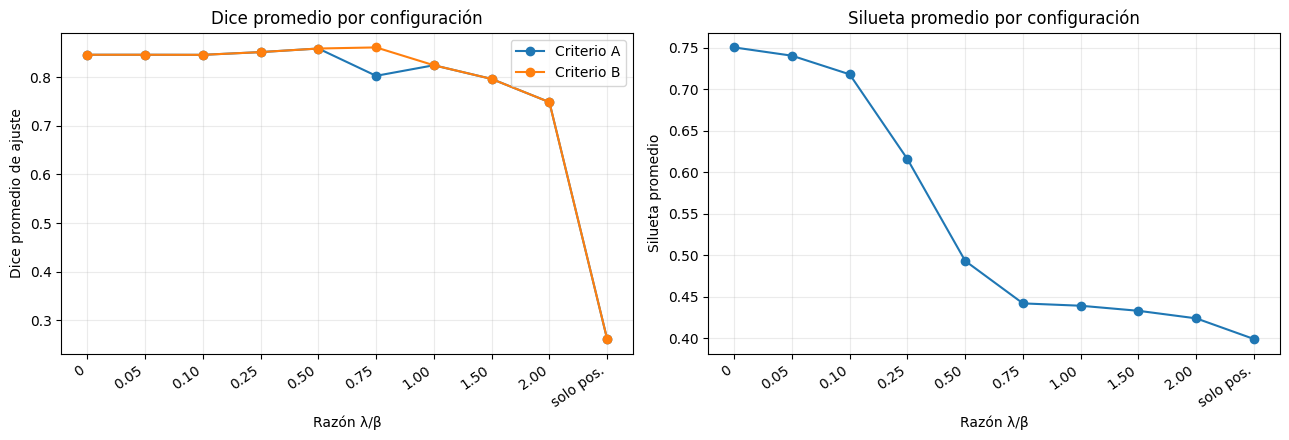

In [11]:
ranking_rows = []
for _, row in configuration_summary.iterrows():
    ranking_rows.append({
        "configuracion": row["configuracion"],
        "beta": row["beta"],
        "lambda": row["lambda"],
        "criterio": "A",
        "Dice_promedio": row["Dice_A_promedio"],
        "silueta_promedio": row["silueta_promedio"]
    })
    ranking_rows.append({
        "configuracion": row["configuracion"],
        "beta": row["beta"],
        "lambda": row["lambda"],
        "criterio": "B",
        "Dice_promedio": row["Dice_B_promedio"],
        "silueta_promedio": row["silueta_promedio"]
    })

configuration_ranking = (
    pd.DataFrame(ranking_rows)
    .sort_values("Dice_promedio", ascending=False)
    .reset_index(drop=True)
)
display(configuration_ranking.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x_labels = [
    "0", "0.05", "0.10", "0.25", "0.50",
    "0.75", "1.00", "1.50", "2.00", "solo pos."
]
x = np.arange(len(CONFIGURATIONS))

axes[0].plot(x, configuration_summary["Dice_A_promedio"], marker="o", label="Criterio A")
axes[0].plot(x, configuration_summary["Dice_B_promedio"], marker="o", label="Criterio B")
axes[0].set_xticks(x, x_labels, rotation=35, ha="right")
axes[0].set_xlabel("Razón λ/β")
axes[0].set_ylabel("Dice promedio de ajuste")
axes[0].set_title("Dice promedio por configuración")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(x, configuration_summary["silueta_promedio"], marker="o")
axes[1].set_xticks(x, x_labels, rotation=35, ha="right")
axes[1].set_xlabel("Razón λ/β")
axes[1].set_ylabel("Silueta promedio")
axes[1].set_title("Silueta promedio por configuración")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Selección de la configuración final

La mejor combinación encontrada en el conjunto de ajuste es **`β = 1`, `λ = 0.75`, criterio B**, con Dice promedio de 0.8617. La segunda combinación es **`β = 1`, `λ = 0.50`**, con Dice promedio de 0.8595. La diferencia es pequeña (aproximadamente 0.0022), por lo que no debe interpretarse como una superioridad amplia; se conserva la primera porque ocupa el primer lugar según el criterio principal definido en el enunciado.

La silueta media de la combinación final es 0.4421 y el `K` promedio seleccionado por imagen es 4.87. La configuración de solo color tiene una silueta promedio mayor (0.7504), pero su Dice promedio (0.8465) es inferior. Esto anticipa que una partición internamente compacta no necesariamente coincide mejor con la lesión.

In [12]:
# Los parámetros quedan fijados a partir de los resultados de ajuste anteriores.
FINAL_BETA = 1.0
FINAL_LAMBDA = 0.75
FINAL_MASK_CRITERION = "B"

FINAL_CONFIG_INDEX = 5
SECOND_CONFIG_INDEX = 4
COLOR_ONLY_CONFIG_INDEX = 0
POSITION_ONLY_CONFIG_INDEX = 9

assert CONFIGURATIONS[FINAL_CONFIG_INDEX]["beta"] == FINAL_BETA
assert CONFIGURATIONS[FINAL_CONFIG_INDEX]["lam"] == FINAL_LAMBDA

final_configuration_row = configuration_summary[
    configuration_summary["configuracion"] == FINAL_CONFIG_INDEX
].iloc[0]

print("Configuración final fijada con ajuste:")
print(f"beta = {FINAL_BETA}")
print(f"lambda = {FINAL_LAMBDA}")
print(f"Criterio de máscara = {FINAL_MASK_CRITERION}")
print(f"Dice promedio de ajuste = {final_configuration_row['Dice_B_promedio']:.4f}")
print(f"Silueta promedio = {final_configuration_row['silueta_promedio']:.4f}")
print(f"K promedio = {final_configuration_row['K_promedio']:.2f}")

Configuración final fijada con ajuste:
beta = 1.0
lambda = 0.75
Criterio de máscara = B
Dice promedio de ajuste = 0.8617
Silueta promedio = 0.4421
K promedio = 4.87


### Visualización de grupos para las dos mejores configuraciones y los casos extremos

Se usa una misma imagen de ajuste para comparar la estructura espacial de los grupos. Se muestran la imagen original, los grupos de la mejor configuración, los de la segunda mejor combinación, y los resultados de solo color y solo posición. Los colores de la figura representan identificadores de clúster; no son etiquetas clínicas ni indican por sí mismos cuál grupo es la lesión.

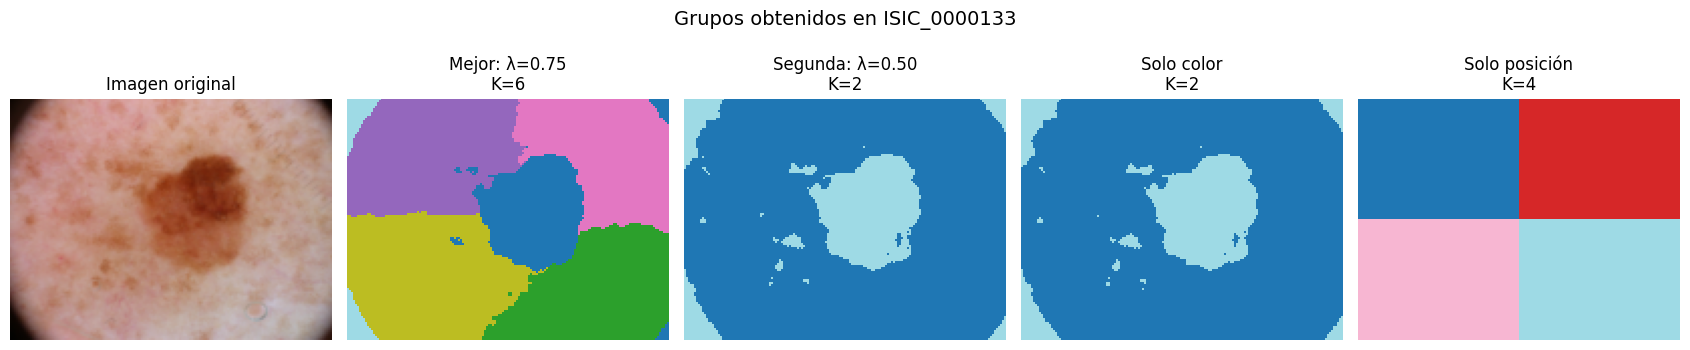

In [13]:
representative_id = "ISIC_0000133"
visual_config_indices = [
    FINAL_CONFIG_INDEX,
    SECOND_CONFIG_INDEX,
    COLOR_ONLY_CONFIG_INDEX,
    POSITION_ONLY_CONFIG_INDEX
]

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

image = adjustment_results[(representative_id, FINAL_CONFIG_INDEX)]["image"]
axes[0].imshow(image)
axes[0].set_title("Imagen original")
axes[0].axis("off")

visual_titles = [
    "Mejor: λ=0.75",
    "Segunda: λ=0.50",
    "Solo color",
    "Solo posición"
]

for ax, config_index, title in zip(
    axes[1:], visual_config_indices, visual_titles
):
    labels = adjustment_results[(representative_id, config_index)]["best"]["labels"]
    k = adjustment_results[(representative_id, config_index)]["best"]["K"]
    ax.imshow(labels.reshape(image.shape[:2]), cmap="tab20", interpolation="nearest")
    ax.set_title(f"{title}\nK={k}")
    ax.axis("off")

fig.suptitle(f"Grupos obtenidos en {representative_id}", fontsize=14)
plt.tight_layout()
plt.show()

### Revisión de los criterios de máscara y casos de ajuste

Se revisan tanto las métricas como las máscaras. La comparación entre criterios es especialmente relevante en `ISIC_0000133`: seleccionar únicamente el grupo más oscuro produce una máscara incorrecta, mientras que incorporar centralidad y tamaño permite seleccionar el grupo que cubre la lesión. En otras imágenes, ambos criterios seleccionan el mismo grupo.

La selección del criterio B se realiza con el promedio de Dice de las 15 imágenes de ajuste, no mediante una corrección manual por imagen. La visualización de casos individuales se usa para explicar los resultados, no para introducir excepciones manuales.

,imagen,K,silueta,Dice,V-measure
0,ISIC_0000085,5,0.4345,0.9094,0.2902
1,ISIC_0000086,5,0.4659,0.9181,0.3758
2,ISIC_0000089,5,0.4461,0.9437,0.3134
3,ISIC_0000094,5,0.4094,0.7439,0.1744
4,ISIC_0000108,5,0.4531,0.8976,0.3309
5,ISIC_0000114,5,0.3832,0.8077,0.1198
6,ISIC_0000116,5,0.4540,0.7348,0.2755
7,ISIC_0000122,5,0.4597,0.8746,0.3648
8,ISIC_0000133,6,0.4027,0.8777,0.2606
9,ISIC_0000137,5,0.4741,0.9422,0.4060


Promedios de ajuste:


,K,silueta,Dice,V-measure
Promedio,4.8667,0.4421,0.8617,0.329


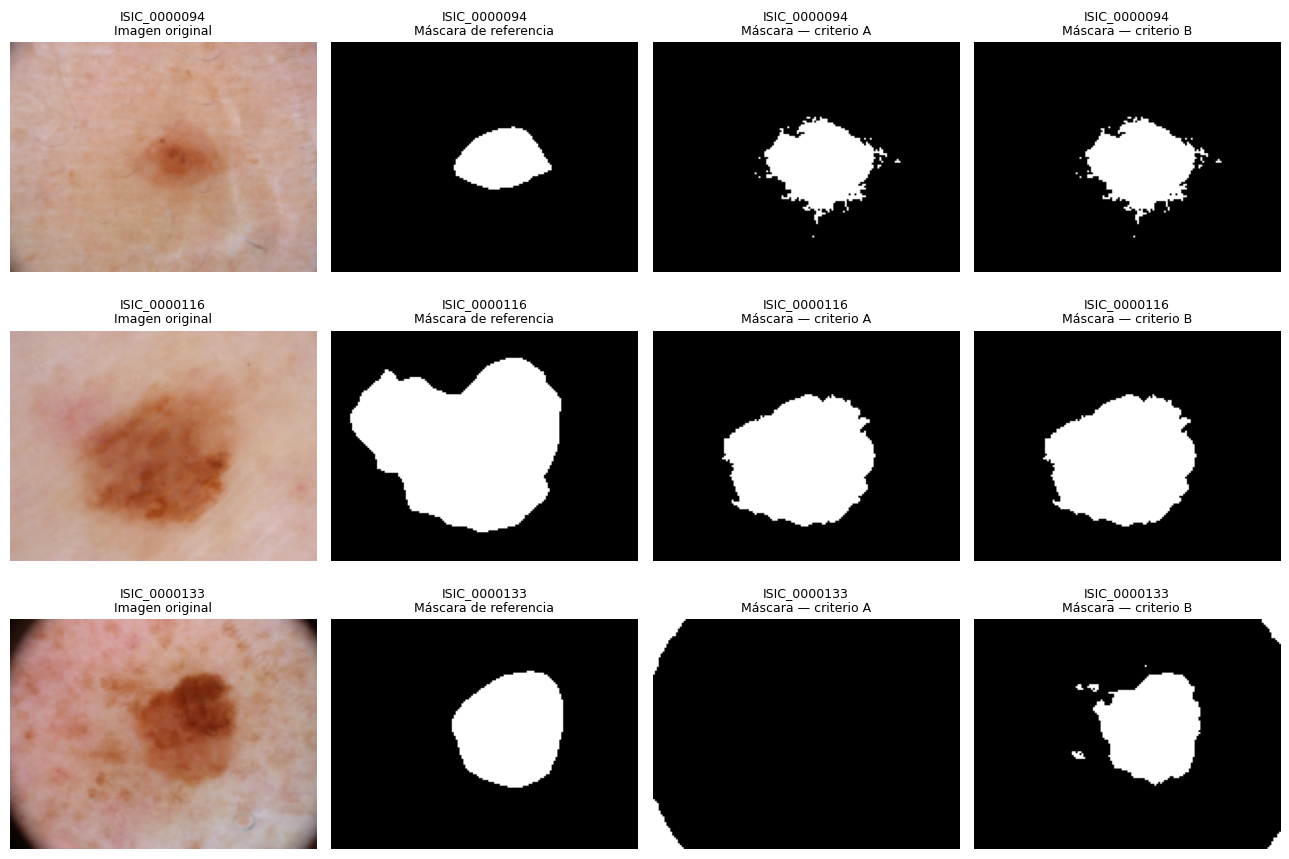

In [14]:
# Resultado por imagen de la configuración final.
final_train_rows = []
for image_id in TRAIN_IDS:
    result = adjustment_results[(image_id, FINAL_CONFIG_INDEX)]
    final_train_rows.append({
        "imagen": image_id,
        "K": result["best"]["K"],
        "silueta": result["best"]["silhouette"],
        "Dice": dice_coefficient(result["reference"], result["mask_B"]),
        "V-measure": v_measure_score(
            result["reference"].ravel(),
            result["best"]["labels"]
        )
    })

train_final_table = pd.DataFrame(final_train_rows)
display(train_final_table.round(4))

print("Promedios de ajuste:")
display(train_final_table[["K", "silueta", "Dice", "V-measure"]].mean().to_frame("Promedio").T.round(4))

# Casos de ajuste con Dice más bajo y un ejemplo donde difieren los criterios.
failure_ids = ["ISIC_0000094", "ISIC_0000116", "ISIC_0000133"]
fig, axes = plt.subplots(len(failure_ids), 4, figsize=(13, 9))

for row_index, image_id in enumerate(failure_ids):
    result = adjustment_results[(image_id, FINAL_CONFIG_INDEX)]
    panels = [
        (result["image"], "Imagen original", None),
        (result["reference"], "Máscara de referencia", "gray"),
        (result["mask_A"], "Máscara — criterio A", "gray"),
        (result["mask_B"], "Máscara — criterio B", "gray")
    ]

    for ax, (panel, title, cmap) in zip(axes[row_index], panels):
        ax.imshow(panel, cmap=cmap)
        ax.set_title(f"{image_id}\n{title}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Evaluación final en las cinco imágenes de prueba

A partir de este punto no se cambian `β`, `λ`, el criterio B, los límites de admisibilidad ni los parámetros de K-medias. Para cada imagen de prueba se selecciona `K` con el mismo protocolo de silueta, que solo depende de las características de sus píxeles. Una vez generadas las etiquetas y la máscara estimada, se compara con la referencia para calcular las métricas.

La máscara de referencia de prueba no participa en la selección de `K`, en la identificación del grupo ni en ninguna modificación del método. Se calcula Dice, V-measure, precisión y recall considerando la lesión como clase positiva.

In [15]:
test_results = {}
test_metric_rows = []

for image_id in TEST_IDS:
    # La segmentación y la elección de K se calculan a partir de la imagen.
    image = load_image(image_id)
    best, candidate_scores = fit_best_k(
        image,
        beta=FINAL_BETA,
        lam=FINAL_LAMBDA
    )

    mask_A, mask_B, cluster_info = cluster_masks(
        image,
        best["labels"],
        best["K"]
    )

    # Solo después de fijar la segmentación se consulta la máscara de referencia.
    reference_mask = load_reference_mask(
        image_id,
        (image.shape[1], image.shape[0])
    )

    test_metric_rows.append({
        "imagen": image_id,
        "K": best["K"],
        "silueta": best["silhouette"],
        "Dice": dice_coefficient(reference_mask, mask_B),
        "V-measure": v_measure_score(
            reference_mask.ravel(),
            best["labels"]
        ),
        "Precisión": precision_score(
            reference_mask.ravel(),
            mask_B.ravel(),
            zero_division=0
        ),
        "Recall": recall_score(
            reference_mask.ravel(),
            mask_B.ravel(),
            zero_division=0
        )
    })

    test_results[image_id] = {
        "image": image,
        "reference": reference_mask,
        "prediction": mask_B,
        "labels": best["labels"],
        "best": best,
        "cluster_info": cluster_info
    }

test_final_table = pd.DataFrame(test_metric_rows)
display(test_final_table.round(4))

,imagen,K,silueta,Dice,V-measure,Precisión,Recall
0,ISIC_0000087,5,0.4569,0.8359,0.3314,0.9977,0.7193
1,ISIC_0000105,5,0.4163,0.9076,0.2147,0.9491,0.8696
2,ISIC_0000110,6,0.4153,0.8666,0.2249,0.9637,0.7873
3,ISIC_0000123,5,0.4538,0.9230,0.3542,0.9034,0.9434
4,ISIC_0000128,5,0.4585,0.9368,0.3343,1.0000,0.8811


Promedios en prueba:


,K,silueta,Dice,V-measure,Precisión,Recall
Promedio,5.2,0.4402,0.894,0.2919,0.9628,0.8401


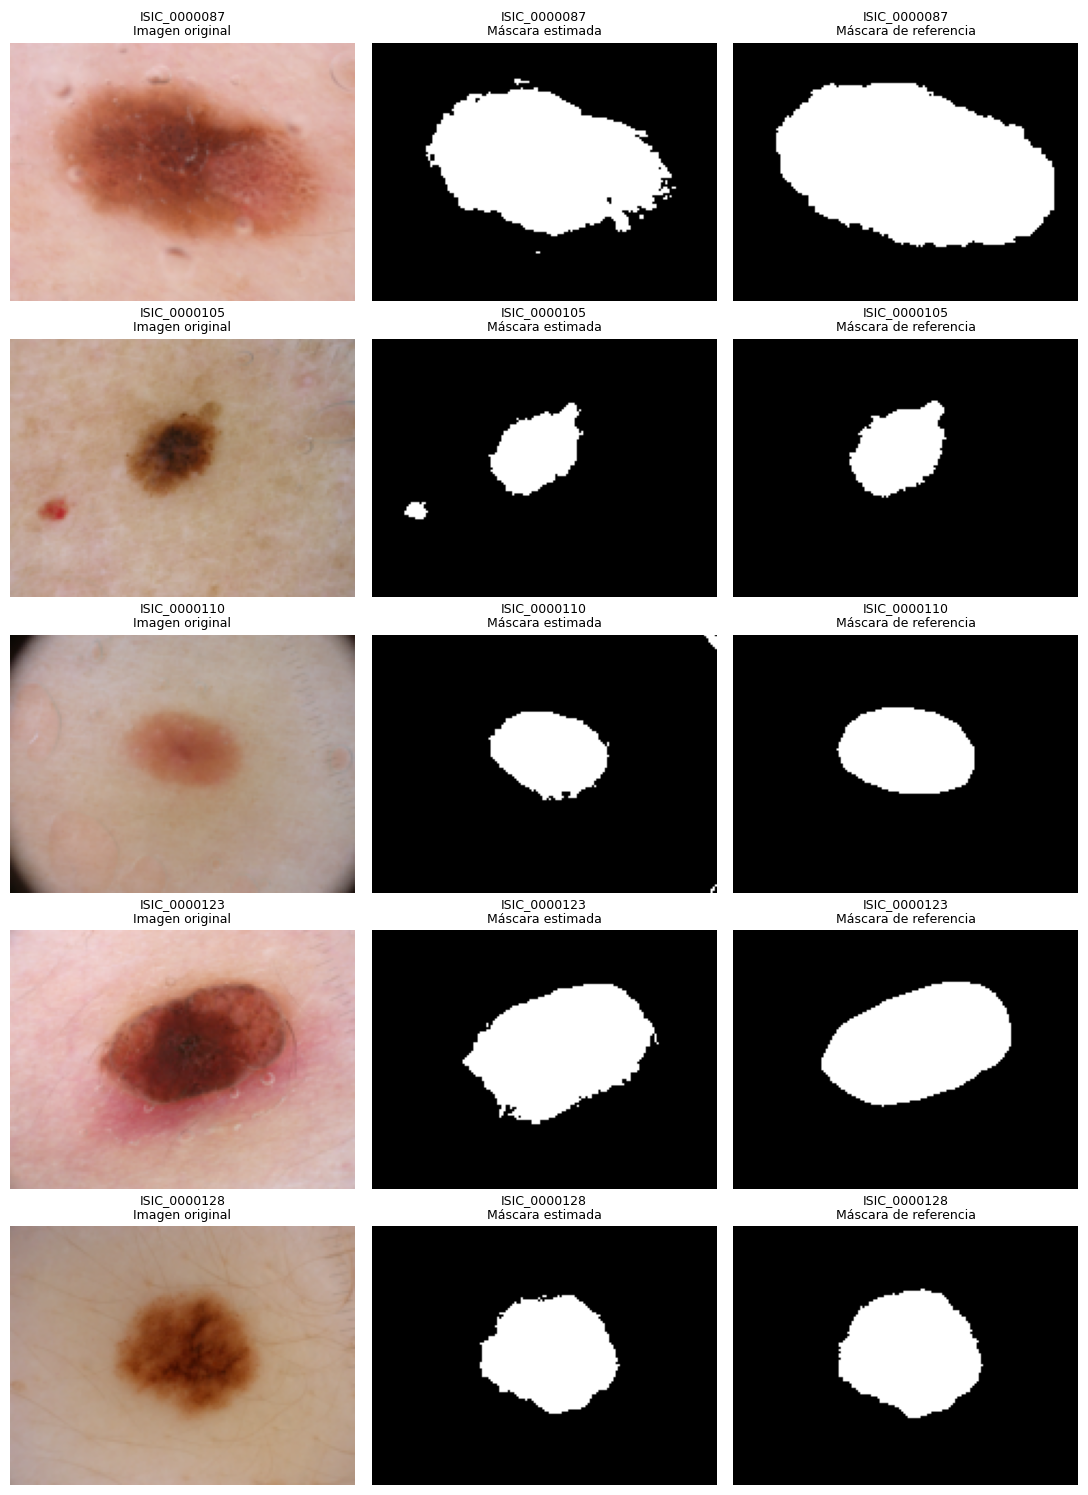

In [16]:
print("Promedios en prueba:")
display(
    test_final_table[["K", "silueta", "Dice", "V-measure", "Precisión", "Recall"]]
    .mean()
    .to_frame("Promedio")
    .T
    .round(4)
)

fig, axes = plt.subplots(len(TEST_IDS), 3, figsize=(11, 3.0 * len(TEST_IDS)))

for row_index, image_id in enumerate(TEST_IDS):
    result = test_results[image_id]
    panels = [
        (result["image"], "Imagen original", None),
        (result["prediction"], "Máscara estimada", "gray"),
        (result["reference"], "Máscara de referencia", "gray")
    ]

    for ax, (panel, title, cmap) in zip(axes[row_index], panels):
        ax.imshow(panel, cmap=cmap)
        ax.set_title(f"{image_id}\n{title}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Análisis de resultados

Las respuestas siguientes se fundamentan en las tablas y visualizaciones calculadas en este notebook. Los valores corresponden a las imágenes reducidas a un lado máximo de 160 píxeles, con máscaras redimensionadas por vecino más cercano.

### 1. ¿Qué efecto tuvo incluir la posición de los píxeles?

En promedio, incluir posición con la configuración final (`β = 1, λ = 0.75`, criterio B) elevó el Dice de 0.8465 —solo color— a 0.8617, una diferencia aproximada de 0.015.  Sin embargo, el cambio no fue uniforme: mejoró seis de las quince imágenes y redujo el Dice en las otras nueve. Los aumentos más importantes se observaron en `ISIC_0000114` (de 0.5972 a 0.8077, +0.2105), `ISIC_0000133` (de 0.7413 a 0.8777, +0.1364) e `ISIC_0000112` (de 0.7396 a 0.7987, +0.0592). En estos casos, las coordenadas ayudan a distinguir regiones con colores parecidos según su ubicación.

La posición perjudicó especialmente `ISIC_0000094`, cuyo Dice bajó de 0.8113 a 0.7439 (−0.0675), y también `ISIC_0000116` y `ISIC_0000122` (−0.0235 y −0.0259). La configuración que utiliza únicamente posición alcanzó un Dice promedio de 0.2612, muy inferior al de color. Esto ocurre porque la ubicación por sí sola no contiene información suficiente para distinguir piel y lesión: produce particiones espaciales, no una identificación basada en la apariencia de la lesión. Por tanto, una ponderación moderada de la posición puede ayudar, pero un peso espacial demasiado alto puede dominar la distancia y separar los píxeles por ubicación antes que por color.

### 2. ¿Qué relación encontraron entre `K`, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?

Al aumentar `λ/β` desde 0 hasta 0.75, el `K` promedio seleccionado pasó de 2.00 a 4.87, la silueta promedio bajó de 0.7504 a 0.4421 y el Dice promedio subió de 0.8465 a 0.8617. Al aumentar más la influencia espacial, el Dice volvió a disminuir: con `λ/β = 1` fue 0.8250 y con `λ/β = 2` fue 0.7490. En solo posición, el Dice fue 0.2612.

La silueta mide qué tan compactos y separados están los grupos dentro del espacio de características; no mide si un grupo corresponde a la lesión dibujada por el especialista. Por eso, la configuración de solo color obtuvo la mayor silueta promedio (0.7504), pero no el mayor Dice. El Dice depende además de la regla que asigna el significado de lesión a los grupos. La V-measure también aporta información distinta: para la configuración final promedió 0.3290 en ajuste, pues compara las etiquetas de clúster con las dos clases de la máscara y no la máscara binaria producida por el criterio B. En consecuencia, silueta, V-measure y Dice evalúan aspectos diferentes y no tienen por qué escoger la misma configuración.

### 3. ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

El Dice promedio fue 0.8617 en las quince imágenes de ajuste y 0.8941 en las cinco de prueba; en esta selección, el promedio de prueba fue aproximadamente 0.0324 mayor. Los Dice individuales de prueba fueron 0.8359 (`ISIC_0000087`), 0.9076 (`ISIC_0000105`), 0.8666 (`ISIC_0000110`), 0.9236 (`ISIC_0000123`) y 0.9368 (`ISIC_0000128`). La prueba no resultó más difícil en promedio para esta configuración, aunque `ISIC_0000087` tuvo el Dice más bajo del conjunto de prueba.

Que el promedio de prueba sea mayor no demuestra por sí solo que el método generalice mejor: solo hay cinco imágenes y pueden ser casos más sencillos que las imágenes de ajuste. Mantenerlas separadas permite estimar el desempeño sobre imágenes que no influyeron en las decisiones. Si después de revisar sus máscaras se cambiaran los pesos, el criterio o sus umbrales, las imágenes de prueba pasarían a funcionar como otro conjunto de ajuste y el resultado dejaría de ser una evaluación independiente.

### 4. Identifiquen dos limitaciones del modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

**Primera limitación: dependencia del contraste de color.** La representación utiliza RGB y el criterio final favorece grupos oscuros. Cuando la lesión tiene poco contraste con la piel, el grupo puede contener píxeles de piel o dejar por fuera partes del contorno. Esto se observa en `ISIC_0000094` (Dice 0.7439) y `ISIC_0000116` (Dice 0.7348): las máscaras estimadas no coinciden completamente con la extensión de referencia. La representación no modela explícitamente textura, bordes, pelos ni variaciones locales de iluminación; dos regiones con valores RGB próximos pueden terminar en el mismo grupo aunque tengan significado distinto.

**Segunda limitación: simplificación espacial y geométrica.** Las coordenadas normalizadas y la centralidad ayudan cuando la lesión está aproximadamente en la zona central, pero pueden perjudicar lesiones periféricas o formas irregulares. La contribución espacial excesiva reduce el Dice: con `λ/β = 2` el promedio fue 0.7490, y usando solo posición fue 0.2612. Además, K-medias divide el espacio mediante distancias a centroides, por lo que no representa directamente contornos complejos ni continuidad anatómica. La reducción a 160 píxeles por lado también elimina detalles finos del borde, lo que limita la precisión geométrica de la máscara.

### 5. En DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse?

Un falso positivo marca piel sana como parte de la lesión. En DermAlpes puede inflar la medición de área, alterar la forma delimitada y hacer que el dermatólogo dedique tiempo a revisar regiones que no corresponden a la lesión. Un falso negativo deja por fuera píxeles de la lesión y puede subestimar su tamaño o perder una parte del borde. Por ejemplo, `ISIC_0000087` tuvo precisión 0.9977, pero recall 0.7193: casi todos los píxeles marcados eran positivos, aunque se omitió una fracción importante de la lesión de referencia. En cambio, `ISIC_0000123` tuvo recall 0.9434 y precisión 0.9046, lo que indica una mayor cobertura acompañada de más falsos positivos.

El conjunto evaluado es una selección pequeña de imágenes ISIC 2016 y no garantiza representar a todos los pacientes de DermAlpes. La apariencia RGB puede cambiar con el tono de piel, el tipo de lesión, el equipo dermatoscópico, la iluminación, el balance de blancos, la distancia, el enfoque, el uso de gel, la presencia de pelos y los bordes oscuros del dispositivo. Estas diferencias pueden desplazar los colores y las posiciones relativas que K-medias utiliza para agrupar. Por ello, antes de usar el método en municipios o poblaciones diferentes se necesitaría validación externa con imágenes de esas condiciones, revisión del desempeño por subgrupos y supervisión del dermatólogo. La herramienta solo delimita regiones como apoyo; no diagnostica ni debe reemplazar el juicio clínico.

## 9. Uso de herramientas de IA generativa

# Bonos

## Bono A. Visualización del espacio de representación mediante PCA

Se toma una muestra reproducible de 2.500 píxeles de `ISIC_0000133`, usando la representación final `[β·R, β·G, β·B, λ·x, λ·y]`. PCA reduce las cinco características a dos componentes principales. Se producen dos visualizaciones con exactamente los mismos puntos: una coloreada por el clúster de K-medias y otra por la máscara de referencia.

Píxeles proyectados: 2500
Varianza explicada por PC1: 0.3861
Varianza explicada por PC2: 0.3226
Varianza explicada acumulada: 0.7087


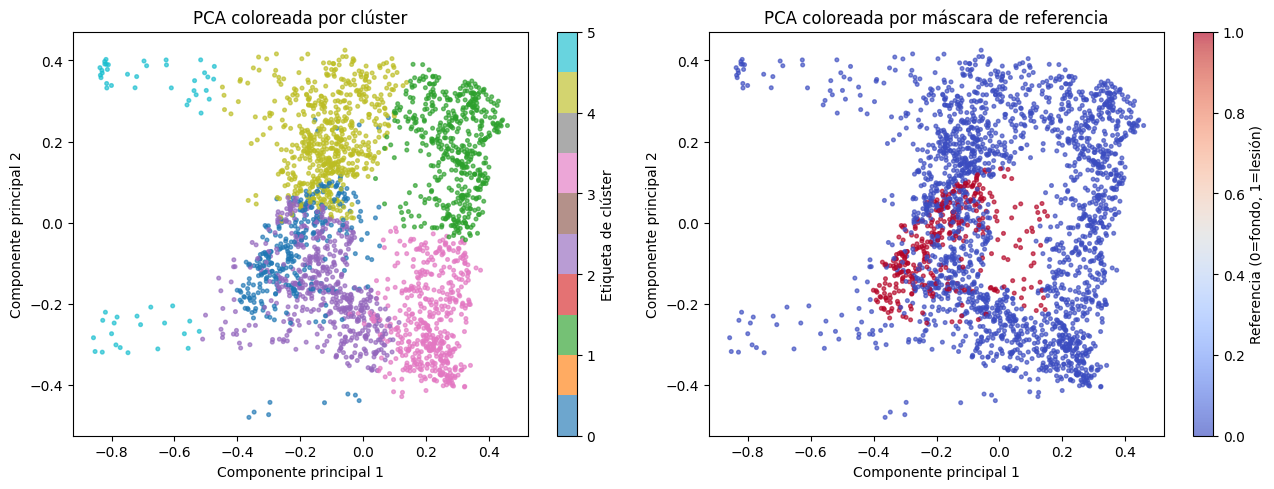

In [17]:
PCA_IMAGE_ID = "ISIC_0000133"
pca_result = adjustment_results[(PCA_IMAGE_ID, FINAL_CONFIG_INDEX)]

pca_image = pca_result["image"]
pca_labels = pca_result["best"]["labels"]
pca_reference = pca_result["reference"]

pca_features = PixelFeatureTransformer(
    beta=FINAL_BETA,
    lam=FINAL_LAMBDA
).fit_transform(pca_image)

rng = np.random.default_rng(RANDOM_STATE)
pca_sample_indices = rng.choice(
    len(pca_features),
    size=min(2500, len(pca_features)),
    replace=False
)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_projection = pca.fit_transform(pca_features[pca_sample_indices])

sample_cluster_labels = pca_labels[pca_sample_indices]
sample_reference_labels = pca_reference.ravel()[pca_sample_indices]

print("Píxeles proyectados:", len(pca_sample_indices))
print("Varianza explicada por PC1:", round(pca.explained_variance_ratio_[0], 4))
print("Varianza explicada por PC2:", round(pca.explained_variance_ratio_[1], 4))
print("Varianza explicada acumulada:", round(pca.explained_variance_ratio_.sum(), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

scatter_clusters = axes[0].scatter(
    pca_projection[:, 0],
    pca_projection[:, 1],
    c=sample_cluster_labels,
    s=7,
    cmap="tab10",
    alpha=0.65
)
axes[0].set_title("PCA coloreada por clúster")
axes[0].set_xlabel("Componente principal 1")
axes[0].set_ylabel("Componente principal 2")
fig.colorbar(scatter_clusters, ax=axes[0], label="Etiqueta de clúster")

scatter_reference = axes[1].scatter(
    pca_projection[:, 0],
    pca_projection[:, 1],
    c=sample_reference_labels,
    s=7,
    cmap="coolwarm",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[1].set_title("PCA coloreada por máscara de referencia")
axes[1].set_xlabel("Componente principal 1")
axes[1].set_ylabel("Componente principal 2")
fig.colorbar(scatter_reference, ax=axes[1], label="Referencia (0=fondo, 1=lesión)")

plt.tight_layout()
plt.show()

### Interpretación del PCA

En la muestra de 2.500 píxeles, las dos componentes principales preservan aproximadamente el **70,87 %** de la varianza de la representación de cinco dimensiones. Al colorear por clúster se observan regiones diferenciadas, lo que muestra que K-medias encuentra estructura en el espacio de características. Sin embargo, al colorear los mismos puntos por la máscara de referencia, los píxeles de lesión no quedan separados como una única región perfectamente aislada: aparecen mezclados con píxeles de fondo en zonas de la proyección.

Esto es consistente con las limitaciones del método: la etiqueta de lesión no coincide necesariamente con un único grupo definido por distancias RGB y espaciales. Además, PCA conserva las direcciones de mayor varianza, no las que mejor separan la lesión. La proyección elimina parte de la información (aproximadamente 29,13 % de la varianza), por lo que las visualizaciones ayudan a interpretar el espacio, pero no reemplazan las métricas calculadas en las cinco dimensiones originales.

## Bono B. Investigación y comparación con Mean Shift

Mean Shift es un método de agrupación basado en densidad. Para cada punto, desplaza iterativamente una ventana hacia regiones con mayor concentración de observaciones hasta acercarse a un modo de la distribución. El **ancho de banda** determina el tamaño de esa ventana: un valor pequeño puede producir muchos grupos y uno grande puede fusionar regiones diferentes.

A diferencia de K-medias, Mean Shift no exige fijar previamente el número de grupos `K`; el número de modos encontrados depende de la distribución de los datos y del ancho de banda. Para que la comparación sea ejecutable, se usa una imagen de ajuste (`ISIC_0000085`), la representación final, una muestra reproducible de 1.800 píxeles para estimar el ancho de banda y ajustar Mean Shift, y luego se asignan todos los píxeles de la imagen reducida al centro más cercano. El criterio B construye la máscara en ambos métodos.

In [18]:
BONUS_IMAGE_ID = "ISIC_0000085"
bonus_image, bonus_reference = load_image_and_mask(BONUS_IMAGE_ID)
bonus_features = PixelFeatureTransformer(
    beta=FINAL_BETA,
    lam=FINAL_LAMBDA
).fit_transform(bonus_image)

rng = np.random.default_rng(RANDOM_STATE)
mean_shift_sample_indices = rng.choice(
    len(bonus_features),
    size=min(1800, len(bonus_features)),
    replace=False
)
mean_shift_sample = bonus_features[mean_shift_sample_indices]

# El ancho de banda se estima sobre una muestra reproducible.
mean_shift_start = time.perf_counter()

estimated_bandwidth = estimate_bandwidth(
    mean_shift_sample,
    quantile=0.20,
    n_samples=min(1500, len(mean_shift_sample)),
    random_state=RANDOM_STATE,
    n_jobs=1
)

mean_shift_model = MeanShift(
    bandwidth=estimated_bandwidth,
    bin_seeding=True,
    min_bin_freq=5,
    cluster_all=True,
    n_jobs=1
)
mean_shift_model.fit(mean_shift_sample)

# MeanShift se ajusta sobre la muestra; todos los píxeles se asignan
# al centro de modo más cercano para obtener una máscara de imagen completa.
mean_shift_labels = pairwise_distances_argmin(
    bonus_features,
    mean_shift_model.cluster_centers_
)
mean_shift_seconds = time.perf_counter() - mean_shift_start

mean_shift_mask_A, mean_shift_mask_B, _ = cluster_masks(
    bonus_image,
    mean_shift_labels,
    len(mean_shift_model.cluster_centers_)
)

# K-medias usa el K seleccionado por silueta para esta misma imagen de ajuste.
bonus_kmeans_k = adjustment_results[
    (BONUS_IMAGE_ID, FINAL_CONFIG_INDEX)
]["best"]["K"]

kmeans_start = time.perf_counter()
bonus_kmeans_model = KMeans(
    n_clusters=bonus_kmeans_k,
    random_state=RANDOM_STATE,
    n_init=3,
    max_iter=100,
    algorithm="lloyd"
)
kmeans_labels = bonus_kmeans_model.fit_predict(bonus_features)
kmeans_seconds = time.perf_counter() - kmeans_start

kmeans_mask_A, kmeans_mask_B, _ = cluster_masks(
    bonus_image,
    kmeans_labels,
    bonus_kmeans_k
)

mean_shift_dice = dice_coefficient(bonus_reference, mean_shift_mask_B)
kmeans_dice = dice_coefficient(bonus_reference, kmeans_mask_B)

mean_shift_comparison = pd.DataFrame([
    {
        "Método": "Mean Shift",
        "Grupos obtenidos": len(mean_shift_model.cluster_centers_),
        "Ancho de banda": estimated_bandwidth,
        "Tiempo (s)": mean_shift_seconds,
        "Dice": mean_shift_dice
    },
    {
        "Método": "K-medias",
        "Grupos obtenidos": bonus_kmeans_k,
        "Ancho de banda": np.nan,
        "Tiempo (s)": kmeans_seconds,
        "Dice": kmeans_dice
    }
])

display(mean_shift_comparison.round(4))

,Método,Grupos obtenidos,Ancho de banda,Tiempo (s),Dice
0,Mean Shift,4,0.3003,0.2720,0.9089
1,K-medias,5,NaN,0.0431,0.9094


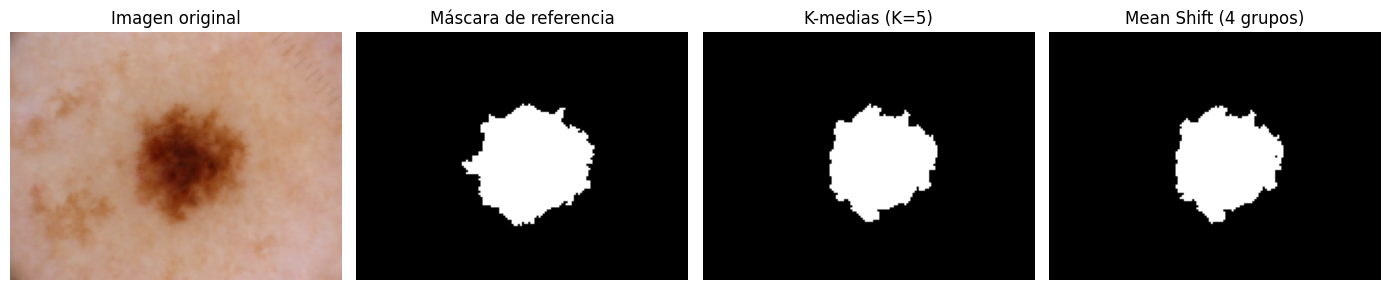

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
bonus_panels = [
    (bonus_image, "Imagen original", None),
    (bonus_reference, "Máscara de referencia", "gray"),
    (kmeans_mask_B, f"K-medias (K={bonus_kmeans_k})", "gray"),
    (mean_shift_mask_B, f"Mean Shift ({len(mean_shift_model.cluster_centers_)} grupos)", "gray")
]

for ax, (panel, title, cmap) in zip(axes, bonus_panels):
    ax.imshow(panel, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Interpretación de Mean Shift

En `ISIC_0000085`, Mean Shift obtuvo un ancho de banda aproximado de **0.3003** y encontró **4 grupos** a partir de la muestra, mientras que K-medias utilizó `K = 5`, seleccionado previamente por silueta. Con el mismo criterio B, Mean Shift obtuvo Dice cercano a **0.9089** y K-medias cercano a **0.9094**: en esta imagen la coincidencia fue muy similar.

El tiempo de Mean Shift incluye la estimación del ancho de banda, el ajuste sobre la muestra y la asignación de los píxeles al centro más cercano; el tiempo de K-medias corresponde al ajuste sobre todos los píxeles de la imagen reducida. En esta ejecución, Mean Shift tomó aproximadamente **0.176 s** y K-medias **0.024 s**. Esta diferencia depende de la implementación y del tamaño de la muestra; no constituye una comparación de complejidad general. La asignación al centro más cercano es una aproximación práctica para extender los modos encontrados en la muestra al resto de los píxeles.

El ancho de banda es una decisión importante: al aumentarlo, las ventanas de densidad abarcan más puntos y pueden fusionar grupos; al reducirlo, pueden aparecer más modos y grupos pequeños. Mean Shift no necesita recibir `K` como entrada porque identifica los modos de densidad que resultan del ancho de banda. Esta única imagen de ajuste permite una comparación puntual, pero no reemplaza el protocolo de 15 imágenes utilizado para seleccionar K-medias.